# Signalverarbeitung

[&larr; Modulübersicht](../00_INTRO.ipynb)

<figure style="text-align:center; margin:1em auto;">
    <img src="img/scipy_logo.png" width=50% />
</figure>

[**SciPy**](https://scipy.org/) (**Sci**entific **Py**thon) erweitert den Umfang von NumPy um viele fundamentale Algorithmen für die Signalverarbeitung, die Optimierung, das Lösen von Gleichungen, etc. Die wichtigsten Module von SciPy sind:

- Signalverarbeitung (*Signal Processing*) - `scipy.signal`
- Integration - `scipy.integrate`
- Interpolation - `scipy.interpolation`
- Statistik (*Statistics*) - `scipy.stats`
- Frequenzanalyse (*Fourier Transform*) - `scipy.fft`
- Optimierung (*Optimization*) - `scipy.optimize`

Wir werden SciPy hier nur grob überfliegen, da wir davon dann vor allem das Modul `scipy.fft` verwenden im Rahmen der **Frequenzanalyse** (vgl. [FFT](../06_FFT/01_FFT.ipynb)). Da SciPy viele andere, nützliche Funktionen enthält, lohnt sich eine kurze Übersicht aber auf jeden Fall. Mittlerweile sollte es dir nicht mehr schwer fallen, eine bestimmte Funktion aus einem Paket/Modul anhand der Dokumentation/Hilfe selbstständig einsetzen zu können.

---

## 🎯 Lernziele

- Du kannst typische Operationen der Signalverarbeitung durchführen (Glättung/Filterung/Interpolation).
- Du beherrscht die numerische Integration bzw. die numerische Ableitung.
- Du weisst, dass in der digitalen Signalverarbeitung mit abgetasteten Signalen gearbeitet wird und weisst, wie Abtastrate $f_S$ und Zeitschrittweite $\Delta t$ bzw. Sampleanzahl $N$ und Messdauer zusammenhängen.
---

## 📋 Blockinhalt

Für die Einführung in SciPy bzw. die selbstständige Einarbeitung stehen die folgenden Notebooks bereit:

1. Einführung (vorliegendes Notebook)
2. Beispielaufgabe im Unterricht [02_SCIPY_Unterricht.ipynb](02_SCIPY_Unterricht.ipynb)
3. Übungsaufgaben [11_SCIPY_Uebungen.ipynb](11_SCIPY_Uebungen.ipynb)

---

## 🛠 Voraussetzungen

Damit wir uns in diesem Teil voll auf die Mathematik konzentrieren können, solltest du mittlerweile das **Arbeiten mit 1D- und 2D-Arrays (NumPy)** sowie das **Plotten (Matplotlib)** im Griff haben. Zudem solltest du von einem Array z. B. Maximum/Minimum/Mittelwert/Standardabweichung bzw. bestimmte Werte/Nulldurchgänge etc. bestimmen können. Darauf werden wir nicht weiter eingehen in diesem Block.

Es werden in diesem Block mathematische Konzepte/Begriffe verwendet (u. a. Filterung, Interpolation, Integration, Ableitung usw.), die du vermutlich schon gehört hast bzw. schon kennst. Falls etwas nicht genügend gut erklärt wird in diesem Notebook, einfach nachfragen oder selber recherchieren.

---

## 1. Motivation

SciPy ist eine Sammlung von mathematischen Algorithmen und Funktionen (basierend auf NumPy) für verschiedene Spezialgebiete. Es erweitert damit unsere "Toolbox" um wichtige Werkzeuge. 

- [SciPy User Guide](https://docs.scipy.org/doc/scipy/tutorial/index.html#user-guide)
- [SciPy Reference](https://docs.scipy.org/doc/scipy/reference/index.html)

### 1.1 Import

Von SciPy werden in der Regel nur die jeweils benötigten Module importiert. Mit `import scipy` kann selbstverständlich auch das gesamte Paket importiert werden.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants, signal, integrate, optimize, interpolate, stats, fft

## 2. Nützliche Funktionen (Auswahl)

Nachfolgend sind nützliche Funktionen aufgelistet, die in vielen praktischen Problemstellungen hilfreich sein können.

### 2.1 Konstanten (`scipy.constants`)

- mathematische/physikalische Konstanten
- Umrechnungsfunktionen in bestimmte Einheiten

In [3]:
print(constants.g)  # Erdbeschleunigung [m/s^2]
print(constants.c)  # Lichtgeschwindigkeit (alternativ: .speed_of_light) [m/s]
print(constants.mach)  # Schallgeschwindigkeit (alternativ: .speed_of_sound) [m/s]

9.80665
299792458.0
340.5


In [4]:
print(constants.inch)  # Zoll/Inch in [m]
print(constants.convert_temperature(25, 'celsius', 'kelvin'))  # Umrechnung von [°C] nach [K]

0.0254
298.15


### 2.2 Signalverarbeitung (`scipy.signal`)

Digitale Signalverarbeitung: ein **Signal** ist ein mit einem fixen Abtastintervall $\Delta t$ (auch Zeitschrittweite genannt) abgetastetes Signal und kann daher ideal in einem Array gespeichert werden. Der Array der Abtastzeitpunkte (Zeitarray) $t_0, t_1, t_2, ..$ kann jederzeit aus der Zeitschrittweite $\Delta t$ erstellt werden (und umgekehrt).

Der Kehrwert des Abtastsintervalls wird Abtastfrequenz genannt.

$$ f_S = \frac{1}{\Delta t} $$

<figure style="text-align:center; margin:1em auto;">
    <img src="img/Signal.svg" width=100% />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Digitale Signalverarbeitung (diskretes/abgetastetes Signal)
    </figcaption>
</figure>

Im Modul `signal` finden sich nützliche Funktionen zur Signalaufbereitung bzw. -konditionierung. Eine herausragende Rolle spielt dabei die Filterung (Tief-/Hochpassfilter etc.). Filter werden in der Regel eingesetzt, um **Signale zu glätten** bzw. bestimmte **Frequenzanteile zu eliminieren/unterdrücken** (z. B. hochfrequentes Rauschen und/oder langsames Driften) oder den **Einfluss von Ausreissern zu reduzieren**.

- `medfilt()` - Medianfilter (gut geeignet, um Ausreisser zu entfernen)
- `savgol_filter()` - Polynomfilter (gut geeignet, um das Signal zu glätten)
- `butter()` - Butterworth-Filter (allg. Tief-/Hoch-/Bandpass bzw. Bandstopp) erstellen (Filter mit `sosfiltfilt()` anwenden, vgl. auch verwandte Funktionen)
- `detrend()` - Trend/Drift aus Signal entfernen
- `decimate()` - Downsampling mit Anti-Aliasing-Filter
- `resample()` - Resampling
- `find_peaks()` - Peaks in einem Signal detektieren
- ...

Auch typische Testsignale finden sich in diesem Modul:

- `square()` - Rechtecksignal
- `sawtooth()` - Sägezahnsignal
- `chirp()` - Chirp-Signal (Schwingung mit ansteigender Frequenz)
- `get_window()` - div. Fensterfunktionen für Frequenzanalyse usw. (vgl. [FFT](../06_FFT/01_FFT.ipynb))

Im nachfolgenden Beispiel wird ein verrauschtes Signal (Messdaten) mit zwei typischen "Smoothing-Filtern" (Medianfilter bzw. Polynomfilter) geglättet.

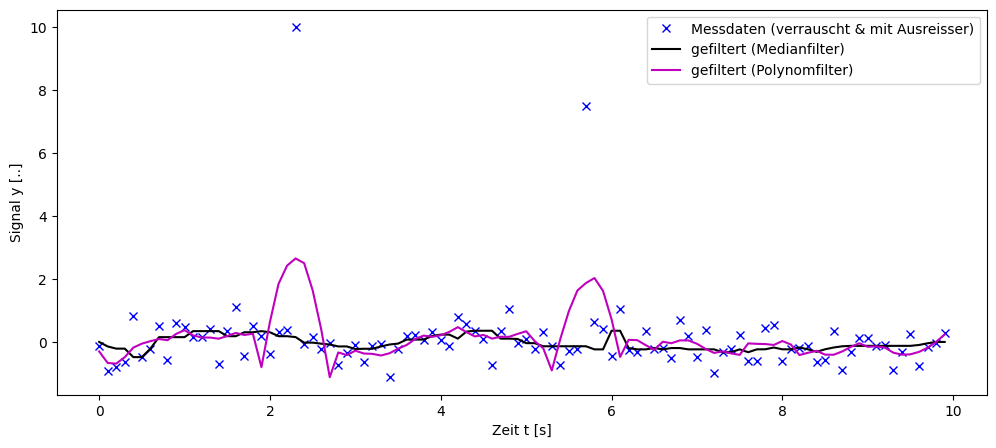

In [5]:
dt = 0.1  # Abtastintervall
t = np.arange(100) * dt  # Zeitarray
y = 0.5 * np.random.randn(100)  # Messdaten simulieren
y[23], y[57] = 10.0, 7.5  # Ausreisser

y_medfilt = signal.medfilt(y, 9)  # Medianfilter mit Fensterlänge 9
y_polfilt = signal.savgol_filter(y, window_length=9, polyorder=3)  # Polynomfilter (kubisch)

plt.figure(figsize=(12, 5))
plt.plot(t, y, 'xb', label='Messdaten (verrauscht & mit Ausreisser)')
plt.plot(t, y_medfilt, 'k', label='gefiltert (Medianfilter)')
plt.plot(t, y_polfilt, 'm', label='gefiltert (Polynomfilter)')
plt.xlabel('Zeit t [s]')
plt.ylabel('Signal y [..]')
plt.legend()
plt.show()

Im nachfolgenden Beispiel wird wiederum ein verrauschtes Signal gefiltert, wobei im Gegensatz zu obigem Beispiel nun eher die gezielte Unterdrückung bestimmter Frequenzen bzw. Frequenzbereiche im Vordergrund steht. Man spricht in diesem Zusammenhang von **Tief- bzw. Hochpassfiltern**, je nach dem welche Frequenzen "durchgelassen" bzw. "blockiert" werden.

☝🏼 Aus der Regelungstechnik kennst du die Verzögerungsglieder ($P-T_1$, $P-T_2$, ...), die Tiefpassverhalten aufweisen. Ein Butterworth-Tiefpassfilter (siehe nachfolgendes Bsp.) kann grob damit verglichen werden, wobei es wie bei den $P-T_{1,2,..}$-Gliedern eine Ordnung und eine Grenzfrequenz gibt. Entsprechend kann ein $D-T_{1,2,..}$-Glied mit dem Butterworth-Hochpassfilter verglichen werden. Kombiniert man Hoch- und Tiefpassfilter, so spricht man vom Bandpassfilter (d. h. ein bestimmtes Frequenzband wird "durchgelassen").

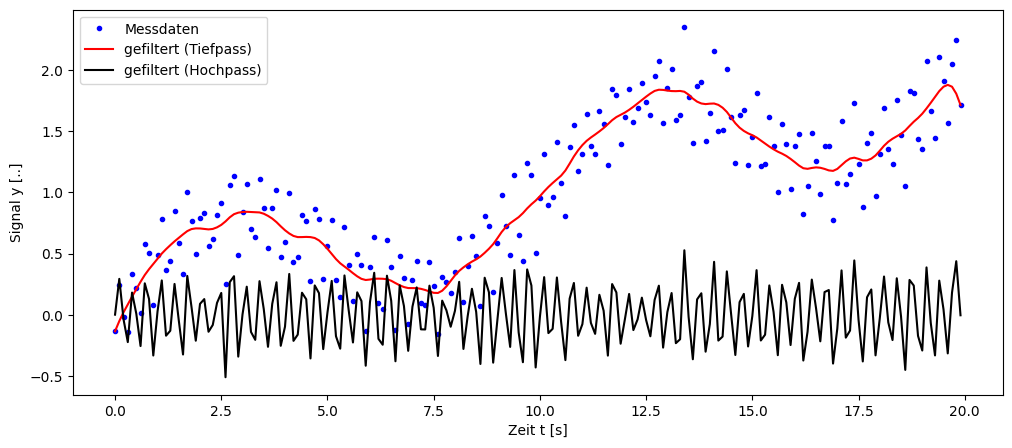

In [6]:
t = np.arange(200) * dt  # Zeitarray
y = (0.1 * t +  
     0.5 * np.sin(2*np.pi*0.1*t) + 
     0.3 * np.sin(2*np.pi*3*t) + 
     0.1 * np.random.randn(200))  # Messdaten simulieren

sos = signal.butter(N=2, Wn=1, btype='lowpass', fs=1/dt, output='sos')  # Butterworth-Tiefpassfilter (Grenzfrequenz 1 Hz)
y_LPF = signal.sosfiltfilt(sos, y)  # Filter anwenden
sos = signal.butter(N=2, Wn=1, btype='highpass', fs=1/dt, output='sos')  # Butterworth-Hochpassfilter (Grenzfrequenz 1 Hz)
y_HPF = signal.sosfiltfilt(sos, y)  # Filter anwenden

plt.figure(figsize=(12, 5))
plt.plot(t, y, '.b', label='Messdaten')
plt.plot(t, y_LPF, 'r', label='gefiltert (Tiefpass)')
plt.plot(t, y_HPF, 'k', label='gefiltert (Hochpass)')
plt.xlabel('Zeit t [s]')
plt.ylabel('Signal y [..]')
plt.legend()
plt.show()

### 2.3 Integration (`scipy.integrate`)

Das Integrieren (und das Ableiten als Gegenstück) spielt in der Signalverarbeitung eine wichtige Rolle. Im Gegensatz zum analytischen Integrieren/Ableiten, das z. T. mit grossem Aufwand verbunden ist, ist das **numerische Integrieren/Ableiten** äusserst unkompliziert. 

#### 2.3.1 Integration

Das Integral eines Signals kann intuitiv als Fläche unter der Kurve (Signal) verstanden werden, was die folgende Abbildung illustriert.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/Integration.svg" width=85% />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Integral als Fläche unter der Kurve
    </figcaption>
</figure>

Betrachtet man die obige Abbildung und überlegt sich, wie man die Fläche unter der Kurve anhand der "Messpunkte" (schwarze Punkte) annähern könnte, so landet man rasch bei der sogenannten *Trapezregel*, d. h. die Fläche kann in vertikale (trapezförmige) Streifen unterteilt werden und diese aufsummiert werden. Das Integral wird damit zu einer Summe und kann ganz einfach berechnet werden.

$$\int y(t) \,dt \approx \sum_{i} \frac{y_i + y_{i-1}}{2} \cdot \Delta t$$

☝🏼 Das Integrieren kommt zum Einsatz, wenn du z. B. einen Beschleunigungsverlauf in den Geschwindigkeitsverlauf bzw. in den Positionsverlauf (Weg) umrechnen musst.

In SciPy stehen dafür die folgenden Funktionen bereit:

- `trapezoid()` - numerische Integration mit Trapezregel
- `cumulative_trapezoid()` - laufende (kumulative) Integration mit Trapezregel
- ...

In [7]:
y = [1, 3, 3, 2, 5, 2, 6, 2, 1, 5, 1]
t = np.linspace(0, 5, len(y))
integral = integrate.trapezoid(y, t)  # numerisches Integral gemäss Trapezregel
print(integral)

15.0


In [8]:
print(integrate.cumulative_trapezoid(y, t))  # numerisches Integral gemäss Trapezregel (kumuliert)

[ 1.    2.5   3.75  5.5   7.25  9.25 11.25 12.   13.5  15.  ]


#### 2.3.2 Ableitung 

Das Gegenstück zur Integration ist die Ableitung. Die Ableitung (Differential) kann intuitiv als Steigung der Kurve verstanden werden.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/Ableitung.svg" width=85% />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Ableitung als Steigung der Kurve
    </figcaption>
</figure>

Auch die Ableitung kann numerisch sehr einfach berechnet werden, nämlich mit dem altbekannten "Steigungsdreieck". Die Ableitung (Differenzialquotient) wird damit zu einem einfachen Quotienten

Zur Berechnung der Ableitung wird am besten die Funktion `gradient()` von NumPy verwendet. Der Begriff *Gradient* ist ein anderes (allgemeineres) Wort für *Steigung*.

$$ \frac{dy(t)}{dt} \approx \frac{y_{i+1} - y_{i-1}}{2 \cdot \Delta t} $$

☝🏼 Das Ableiten kommt zum Einsatz, wenn du z. B. aus einem Positionsverlauf (Weg) den Geschwindigkeitsverlauf bzw. den Beschleunigungsverlauf bestimmen musst.

☝🏼 Das Ableiten ist sehr sensitiv auf hochfrequente Anteile (z. B. Rauschen) - denke hierzu an das Bode-Diagramm des D-Gliedes - daher wird das Signal in der Regel vor dem Ableiten gefiltert (siehe oben).

In [9]:
ableitung = np.gradient(y, t)  # Ableitung (mit NumPy)
print(ableitung)

[ 4.  2. -1.  2.  0.  1.  0. -5.  3.  0. -8.]


### 2.4 Interpolation (`scipy.interpolate`)

Die Interpolation wird verwendet, um z. B. Werte zwischen tatsächlichen Messpunkten "abzulesen" oder um z. B. ein Signal im Nachhinein mit einer anderen zeitlichen Auflösung (Abtastfrequenz) abzutasten.

- `CubicSpline()` - Kubische Interpolation
- `BSpline()` - B-Spline-Interpolation
- ...

Für die lineare Interpolation wird am besten die Funktion `interp()` von NumPy verwendet.

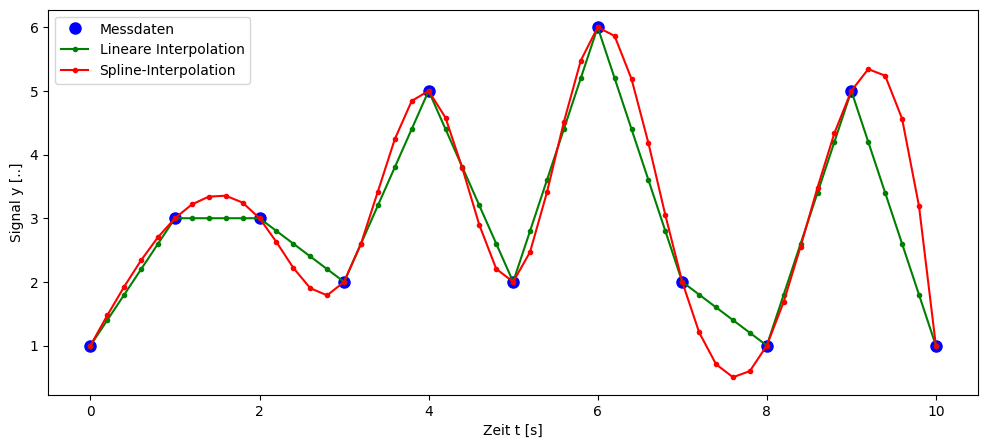

In [18]:
t = np.arange(11)  # Zeitarray
y = [1, 3, 3, 2, 5, 2, 6, 2, 1, 5, 1]  # Messdaten

t_interp = np.linspace(0, max(t), 51)  # Stützstellen für Interpolation

y_lin_interp = np.interp(t_interp, t, y)  # lin. Interpolation

spline = interpolate.CubicSpline(t, y)  # Spline-Interpolation
y_interp = spline(t_interp)  

plt.figure(figsize=(12, 5))
plt.plot(t, y, 'ob', ms=8, label='Messdaten')
plt.plot(t_interp, y_lin_interp, 'g.-', label='Lineare Interpolation')
plt.plot(t_interp, y_interp, 'r.-', label='Spline-Interpolation')
plt.xlabel('Zeit t [s]')
plt.ylabel('Signal y [..]')
plt.legend()
plt.show()

☝🏼 Bei der Interpolation (egal ob linear oder nicht) geht die Interpolationskurve immer "durch" die Messpunkte.

### 2.5 Statistik (`scipy.stats`)

In diesem Modul sind nützliche Funktionen für statistische Analysen (statistische Grössen, Verteilungen (z. B. `norm` für die Normalverteilung), Hypothesentests etc.) enthalten. Wir haben die wichtigsten Grundlagen der Statistik im vergangenen Unterrichtsblock behandelt und werden in diesem Bereich daher nicht weiter vorstossen. Lediglich die **lineare Regression** (*Ausgleichsrechnung*) soll an dieser Stelle behandelt werden, da sie sich in sehr vielen Gebieten als nützliches Werkzeug etabliert hat.

- `linregress()` - lineare Regression (Gerade an Daten "fitten")
- `pearsonr()` - Korrelationskoeffizient
- ...

Die Funktion `linregress()` wird verwendet, um ein lineares Modell ("Geradengleichung") an Messdaten zu fitten - man spricht dann von einer *Ausgleichsgeraden* oder *Regressionsgeraden*. Stell dir vor, du müsstest den elektrischen Widerstand eines Bauteils bestimmen (anhand von Strom- und Spannungsmessungen). Du könntest nur eine einzige Messung machen, doch dann wäre eine allgemeingültige/aussagekräftige Aussage nur begrenzt möglich. Besser ist es, mehrere Messungen mit unterschiedlichen Strömen/Spannungen durchzuführen und dann alle Messungen zu berücksichtigen. Gemäss $U = R \cdot I$ kann der Widerstand $R$ als Steigung im U-I-Diagramm bestimmt werden, was mit der linearen Regression erreicht werden kann. Die Steigung der *Ausgleichsgeraden* entspricht dann dem "mittleren Widerstand" (d. h. dem besten Schätzwert).

Im folgenden Beispiel wird dies illustriert. 

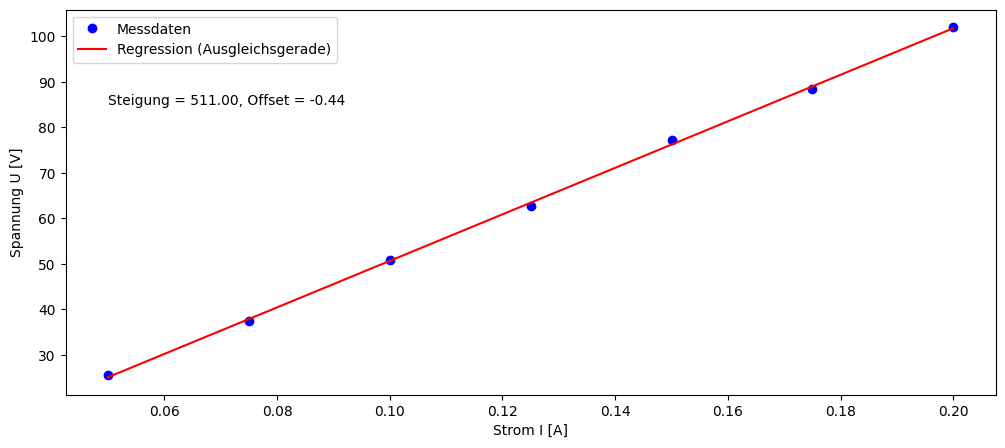

In [12]:
I = np.linspace(5, 20, 7)/100  # Strom [A]
U = 500 * I + 2 * np.random.randn(7)  # Messdaten simulieren - Spannung [V]

res = stats.linregress(I, U)  # lineare Regression
U_fit = res.intercept + res.slope * I  # Modell

plt.figure(figsize=(12, 5))
plt.plot(I, U, 'ob', label='Messdaten')
plt.plot(I, U_fit, 'r', label='Regression (Ausgleichsgerade)')
plt.text(0.05, 85.0, "Steigung = {:.2f}, Offset = {:.2f}".format(res.slope, res.intercept))
plt.xlabel('Strom I [A]')
plt.ylabel('Spannung U [V]')
plt.legend()
plt.show()

☝🏼 Man stellt fest, dass die *Ausgleichsgerade* i. Allg. nicht genau durch die Messpunkte geht (es ist also komplett etwas anderes als eine Interpolation). Die *Ausgleichsgerade* wird "optimal" an die Messpunkte angepasst (*gefittet*), so dass die Summe der Abweichungen zu den Messpunkten gesamthaft minimal ausfällt. (Wenn du in einem Excel-Diagramm z. B. eine *Trendlinie* hinzufügst, wird im Hintergrund genau das gemacht.)

### 2.6 Frequenzanalyse/Fouriertransformation (`scipy.fft`)

Damit werden wir intensiv arbeiten im Block Frequenzanalyse (vgl. [FFT](../06_FFT/01_FFT.ipynb)) und daher an dieser Stelle noch nicht darauf eingehen.

- `fft()` - allg. FFT-Funktion
- `rfft()` - FFT für reelle Signale
- `rfftfreq()` - Frequenzachse berechnen für FFT (für reelle Signale)
- ...

---

## 💡 Verständnisfragen

- Warum werden Tiefpassfilter eingesetzt? Was könnte ein Anwendungsfall für einen Hochpassfilter sein?
- Erkläre in eigenen Worten was Integrieren bzw. Ableiten (Differenzieren) bedeutet.
- Erkläre (z. B. anhand des Bode-Diagramms), warum hochfrequenzte Anteile (Rauschen) beim Integrieren kein erhebliches Problem darstellen (im Gegensatz zum Ableiten).
- Erkläre den Begriff *Interpolation*.
- Erkläre den Unterschied zwischen *Interpolation* und *Regression*/*Ausgleichsrechnung*.

---

## A. Anhang

Nachfolgend sind weitere Module/Anwendungen von SciPy aufgeführt. Diese kannst du bei Interesse anschauen, doch die Inhalte gehören nicht zum eigentlichen Stoffumfang des Moduls.

### A.1 Optimierung bzw. Gleichungslöser (`scipy.optimize`)

In diesem Modul finden sich Algorithmen für das Optimieren (Finden von Minima, Nullstellen etc. bzw. Lösen von Gleichungssystemen, Einpassen von Modellen in Messdaten etc.). Damit werden wir uns im Unterricht nicht weiter befassen.

- `minimize_scalar()` - Optimierung einer Funktion mit einer Variable
- `minimize()` - Optimierung einer Funktion mit mehreren Variablen
- `root_scalar()` - Lösen einer skalaren Funktion
- `root()` - Lösen einer Vektorfunktion
- `least_squares()` - Nichtlineare Optimierung mit Randbedingungen
- `curve_fit()` - Ausgleichsrechnung (Regression) für beliebige nichtlineare Funktion

☝🏼 Eine typische Anwendung eines solchen Solvers ist z. B. die Gelenkwinkel eines Roboters für eine bestimmte Position/Orientierung des Greifers (*End Effectors*) zu berechnen (vgl. Unterrichtsbeispiel zur Vektorrechnung).

Ein typischer Anwendungsfall solcher Optimierungsalgorithmen ist z. B. wenn man eine beliebige mathematische Funktion (in diesem Zusammenhang auch Modell genannt) an Messdaten "anpassen" möchte (dies wird "fitten" genannt und die entsprechende SciPy-Funktion entsprechend `curve_fit()`) - es handelt sich dabei sozusagen um die Erweiterung der linearen Regression (vgl. oben), um nun beliebige (auch nichtlineare) Modelle verwenden zu können. Ein Anwendungsfall wäre z. B. die Identifikation einer gemessenen Sprungantwort eines $P-T_1$-Gliedes (siehe nachfolgendes Beispiel).

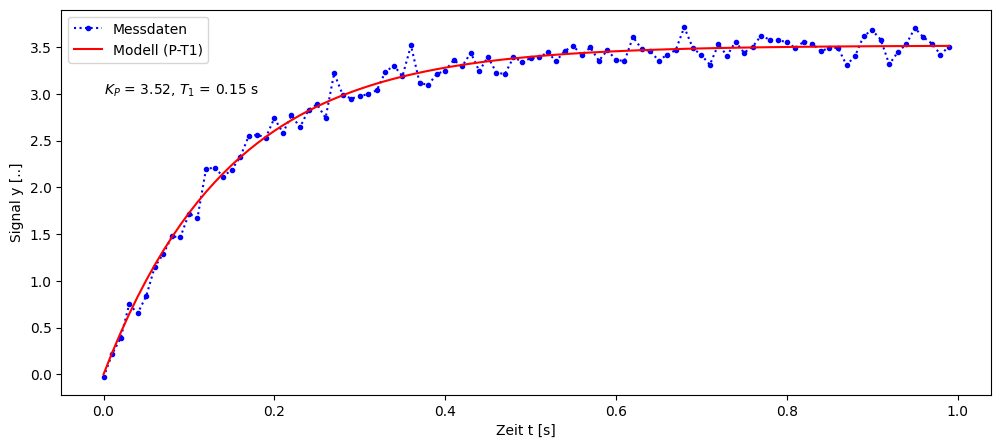

In [20]:
y = np.loadtxt('data/Messdaten.csv')  # Messdaten [..]
dt = 0.01  # Abtastintervall [s]
t = np.arange(len(y)) * dt  # Zeitarray [s]

def pt1(t, K_P, T_1):
    return K_P * (1-np.exp(-t/T_1))  # Modell (Funktion) eines P-T1-Gliedes

popt, pcov = optimize.curve_fit(pt1, t, y)  # Modell wird "gefittet"
 
plt.figure(figsize=(12, 5))
plt.plot(t, y, '.b:', label='Messdaten')
plt.plot(t, pt1(t, *popt), 'r', label='Modell (P-T1)')
plt.text(0.0, 3.0, "$K_P$ = {:.2f}, $T_1$ = {:.2f} s".format(*popt))
plt.xlabel('Zeit t [s]')
plt.ylabel('Signal y [..]')
plt.legend()
plt.show()

Natürlich können ganz viele verschiedene Probleme mit solchen Solvern gelöst werden. Nachfolgend wird als Demo eine Lösung (Nullstelle) sowie das Minimum der kubischen Gleichung $ f(x) = 0.1 x^3 + 0.75 x^2 - 1.5 x - 2 $ gesucht. Im Gegensatz zu einer quadratischen Gleichung (Parabel) gibt es dafür keine einfache Formel.

In [21]:
def f(x):
    return 0.1*x**3 + 0.75*x**2 - 1.5*x - 2  # Gleichung (Funktion), die gelöst werden soll

loesung = optimize.root_scalar(f, x0=2)  # eine der Lösungen (Nullstelle) der obigen Gleichung  f(x)
print('Nullstelle bei x =', loesung.root)  # Nullstelle

Nullstelle bei x = 2.372969680465611


In [22]:
minimum = optimize.minimize_scalar(f)  # lokales Minimum (Scheitelpunkt) der obigen Funktion f(x)
print('(lokales) Minimum =',minimum.fun)  # Minimum
print('Minimum befindet sich an Stelle x =',minimum.x)  # x-Wert des Minimums

(lokales) Minimum = -2.67172942406179
Minimum befindet sich an Stelle x = 0.8541019574849233


Damit wir uns überzeugen können, dass die obige Nullstelle bzw. das Minimum korrekt bestimmt wurden, können wir die Funktion plotten.

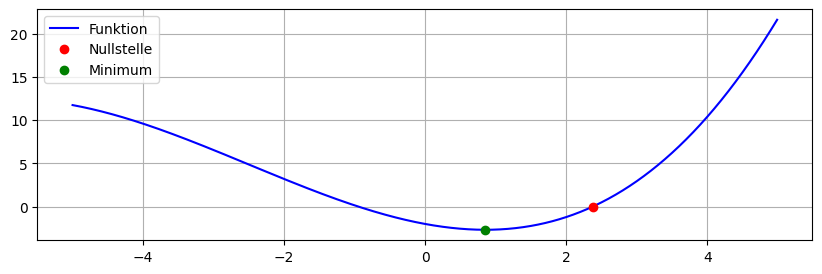

In [23]:
x = np.arange(-5, 5, 0.01)
y = f(x)
plt.figure(figsize=(10, 3))
plt.plot(x, y, 'b-', label='Funktion')
plt.plot(loesung.root, 0, 'ro', label='Nullstelle')
plt.plot(minimum.x, minimum.fun, 'go', label='Minimum')
plt.grid()
plt.legend()
plt.show()

☝🏼 Überlege kurz, wie du die Nullstelle bzw. das Minimum (oder das Maximum) der obigen Funktion alternativ "von Hand" (also ohne SciPy) bestimmen könntest, wenn der Funktionsverlauf als Array vorliegt.

#### A.1.1 Praxisanwendung: Bestimmen der Gelenkwinkel eines Roboterarms

Im Unterrichtsblock zur Vektorrechnung haben wir eine Roboterbewegung anhand von vorgegebenen Gelenkwinkeln simuliert und die Trajektorie dargestellt. Der umgekehrte Weg, d. h. die Gelenkwinkel eines Roboters anhand der Zielposition (Trajektorie) zu bestimmen, ist generell - vor allem bei Robotern mit vielen Achsen/Gelenken - schwieriger und wird daher typischerweise mit numerischen Optimierungsverfahren gelöst.

Nachfolgend werden die Gelenkwinkel für den im Unterrichtsblock zur Vektorrechnung verwendeten Roboterarm für eine bestimmte Trajektorie mittels numerischer Optimierung bestimmt.

In [24]:
arm_1 = np.array([1.0, 0])  # Arm 1 ("Unterarm") in Nullstellung
arm_2 = np.array([0.5, 0])  # Arm 2 ("Oberarm") in Nullstellung

def R(phi):  # Rotationsmatrix (2D)
    return np.array([[np.cos(phi), -np.sin(phi)],
                     [np.sin(phi), np.cos(phi)]])

Für die Optimierung definieren wir nun eine Funktion, die für gegebene Winkel die Abweichung zwischen Roboterposition und der Zielposition zurückgibt. Diese Funktion wird während der Optimierung "minimiert", d. h. für alle Bahnpunkte der Trajektorie werden die Winkel "gesucht", die den Roboterarm exakt positionieren.

In [25]:
def deviation(angle, target):
    return R(angle[0])@(arm_1 + R(angle[1])@arm_2) - target

Die vorgegebene Trajektorie (Bahn), die der Roboterarm abfahren soll, wird nachfolgend eingelesen und dargestellt.

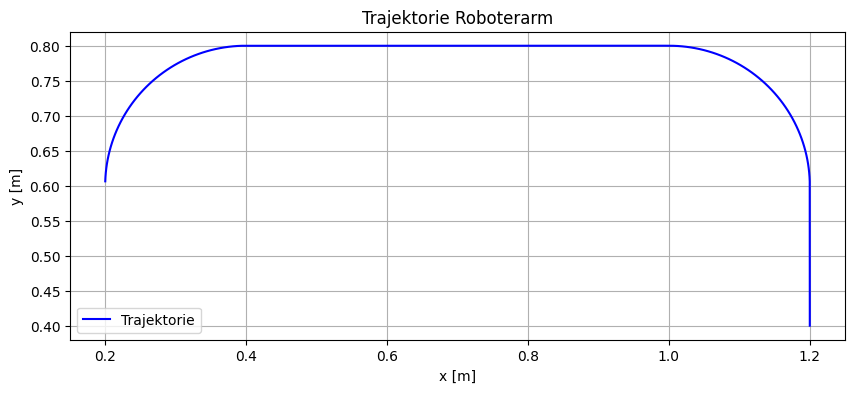

In [26]:
targets = np.loadtxt('data/targets.txt')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(targets[:,0], targets[:,1], 'b', label='Trajektorie')
ax.set_xlabel('x [m]')
ax.set_ylabel('y [m]')
ax.set_title('Trajektorie Roboterarm')
ax.legend()
ax.grid()
plt.show()

Nun folgt der in Bezug auf diesen Unterrichtsblock relevante/interessante Teil. Nachfolgend wird die Optimierung durchgeführt. Für jeden "Zeitschritt" werden die optimalen ("korrekten") Winkel bestimmt, welche die Abweichung zwischen Roboterposition und Zielposition (Trajetorie) möglichst klein (= 0) werden lassen.

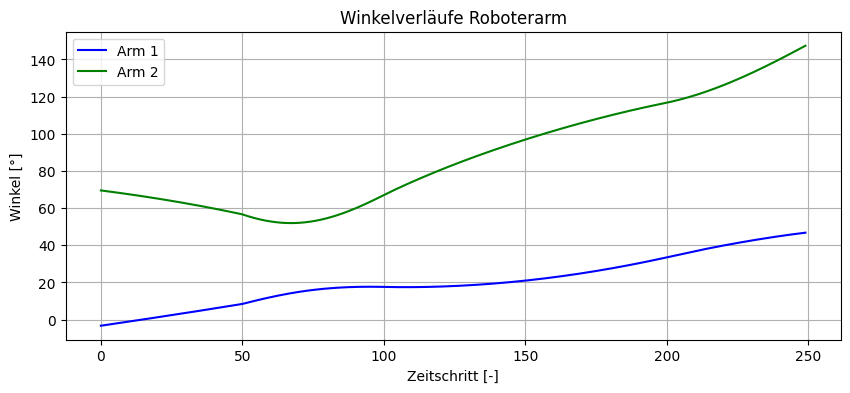

In [27]:
N = len(targets)  # Anzahl Zeitschritte
angles = np.zeros((N,2))
for i in range(N):
    angles[i] = optimize.least_squares(fun=deviation, x0=np.array([0, 1]), args=(targets[i],)).x

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.rad2deg(angles[:,0]), 'b', label='Arm 1')
ax.plot(np.rad2deg(angles[:,1]), 'g', label='Arm 2')
ax.set_xlabel('Zeitschritt [-]')
ax.set_ylabel('Winkel [°]')
ax.set_title('Winkelverläufe Roboterarm')
ax.legend()
ax.grid()
plt.show()

Mit den oben berechneten Winkelverläufen können nun die Roboterpositionen bestimmt werden. Da dies im Unterrichtsblock zur Vektorrechnung gemacht wird, wird an dieser Stelle darauf verzichtet. Nachfolgend wird lediglich die Animation (GIF) davon gezeigt.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/Robot.gif" />
</figure>